In [3]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from glob import glob
import pandas as pd
from collections import defaultdict, Counter
from pathlib import Path
from PIL import Image
import seaborn as sns
import random
import seaborn as sns
from skimage.feature import graycomatrix, graycoprops
import json
import seaborn as sns


In [4]:
with open("../data/Train/CAM_Instance_Train.json", "r") as f:
    coco_data = json.load(f)
image_info = {img["id"]: img for img in coco_data["images"]}
category_info = {cat["id"]: cat["name"] for cat in coco_data["categories"]}
rows = []
for ann in coco_data["annotations"]:
    img = image_info[ann["image_id"]]
    cat_name = category_info[ann["category_id"]]
    x, y, w, h = ann["bbox"]
    rows.append({
        "image_id": ann["image_id"],
        "file_name": img["file_name"],
        "category_id": ann["category_id"],
        "category_name": cat_name,
        "bbox": ann["bbox"],         
        "area": ann["area"],
        "iscrowd": ann["iscrowd"],
        "bbox_x": x,
        "bbox_y": y,
        "bbox_width": w,
        "bbox_height": h,
    })
df = pd.DataFrame(rows)
df.head()

,image_id,file_name,category_id,category_name,bbox,area,iscrowd,bbox_x,bbox_y,bbox_width,bbox_height
0,1,COD10K-CAM-1-Aquatic-1-BatFish-8.jpg,1,foreground,"[70.0, 40.0, 315.0, 559.0]",68427,0,70.0,40.0,315.0,559.0
1,2,COD10K-CAM-1-Aquatic-1-BatFish-9.jpg,1,foreground,"[63.0, 152.0, 495.0, 270.0]",57218,0,63.0,152.0,495.0,270.0
2,3,COD10K-CAM-1-Aquatic-2-ClownFish-12.jpg,1,foreground,"[152.0, 415.0, 119.0, 97.0]",6412,0,152.0,415.0,119.0,97.0
3,3,COD10K-CAM-1-Aquatic-2-ClownFish-12.jpg,1,foreground,"[311.0, 64.0, 59.0, 74.0]",2301,0,311.0,64.0,59.0,74.0
4,4,COD10K-CAM-1-Aquatic-2-ClownFish-14.jpg,1,foreground,"[1081.0, 86.0, 165.0, 148.0]",12439,0,1081.0,86.0,165.0,148.0


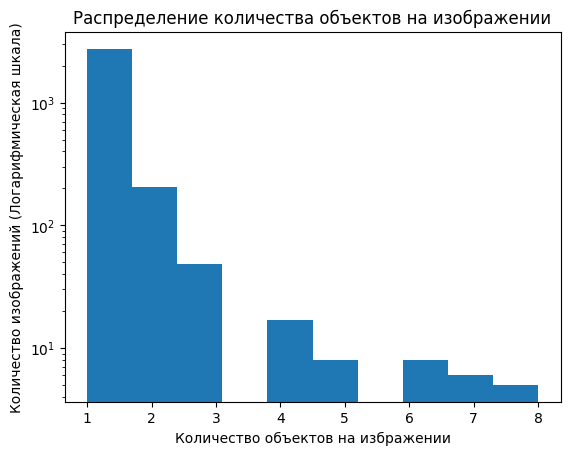

In [5]:
count_images = df.groupby(by = "file_name").agg(count_object = ("image_id","count")).reset_index().sort_values(by = "count_object",ascending=False)
plt.yscale("log") 
plt.hist(count_images["count_object"])
plt.title("Распределение количества объектов на изображении")
plt.xlabel("Количество объектов на избражении")
plt.ylabel("Количество изображений (Логарифмическая шкала)")
plt.show()

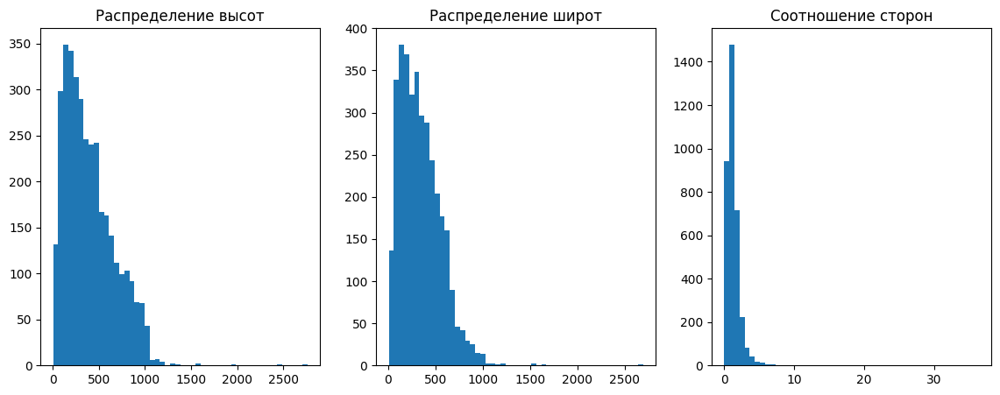

In [5]:
fig, axes = plt.subplots(1, 3, figsize = (14,5))
axes[0].hist(df["bbox_width"],bins = 50)
axes[0].set_title("Распределение высот")
axes[1].hist(df["bbox_height"],bins = 50)
axes[1].set_title("Распределение широт")
axes[2].hist(df["bbox_width"]/df["bbox_height"],bins = 50)
axes[2].set_title("Соотношение сторон")
plt.show()

In [6]:
folder_path = Path("../data/Train/Image")
sizes = set()

for file_path in folder_path.iterdir():
        try:
            with Image.open(file_path) as img:
                sizes.add((img.height, img.width))
        except Exception:
            print(f"Ошибка чтения файла: {file_path.name}")

if len(sizes) == 1:
    print("Одинаковые размеры файлов")
elif len(sizes) > 1:
    print("Разные размеры файловв")


Разные размеры файловв


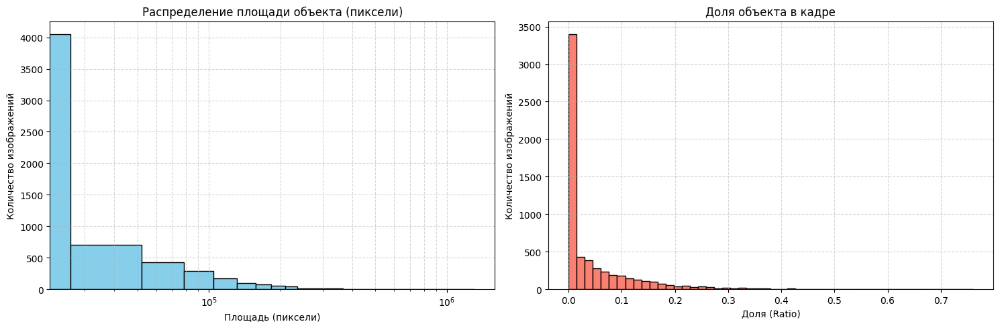

In [7]:
mask_path_g = Path("../data/Train/GT_Object")
mask_stats = {
    "object_area": [],  
    "obj_ratio": [],    
    "bbox_area": []     }
for mask_path in mask_path_g.glob("*.*"):
    if mask_path.suffix.lower() not in ['.png', '.jpg', '.jpeg', '.bmp']:
        continue
        
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        continue  
    h, w = mask.shape
    binary_mask = mask > 0
    obj_pixels = np.sum(binary_mask)
    total_pixels = h * w
    if obj_pixels > 0:
        y_indices, x_indices = np.where(binary_mask)
        bbox_h = np.max(y_indices) - np.min(y_indices) + 1
        bbox_w = np.max(x_indices) - np.min(x_indices) + 1
        bbox_area = bbox_h * bbox_w
    else:
        bbox_area = 0  
    mask_stats["object_area"].append(obj_pixels)
    mask_stats["obj_ratio"].append(obj_pixels / total_pixels)
    mask_stats["bbox_area"].append(bbox_area)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(mask_stats["object_area"], bins=50, color='skyblue', edgecolor='black')
axes[0].set_title("Распределение площади объекта (пиксели)")
axes[0].set_xlabel("Площадь (пиксели)")
axes[0].set_ylabel("Количество изображений")
axes[0].set_xscale("log") 
axes[0].grid(True, which="both", ls="--", alpha=0.5)

axes[1].hist(mask_stats["obj_ratio"], bins=50, color='salmon', edgecolor='black')
axes[1].set_title("Доля объекта в кадре")
axes[1].set_xlabel("Доля (Ratio)")
axes[1].set_ylabel("Количество изображений")
axes[1].grid(True, ls="--", alpha=0.5)

plt.tight_layout()  
plt.show()

In [8]:
df['img_width'] = df['image_id'].map(lambda x: image_info[x]['width'])
df['img_height'] = df['image_id'].map(lambda x: image_info[x]['height'])
df['img_area'] = df['img_width'] * df['img_height']

df['obj_ratio'] = df['area'] / df['img_area']
df['bbox_aspect_ratio'] = df['bbox_width'] / df['bbox_height']

Добавим дополнительные признаки в dataframe

In [9]:
df["img_width"] = df["image_id"].map(lambda x: image_info[x]["width"])
df["img_height"] = df["image_id"].map(lambda x: image_info[x]["height"])
df["img_area"] = df["img_width"] * df["img_height"]
df["obj_ratio"] = df["area"] / df["img_area"]
df["bbox_aspect_ratio"] = df["bbox_width"] / df["bbox_height"]

Также добавим количетсво полигонов на объект

In [10]:
poly_counts = []
for ann in coco_data["annotations"]:
    poly_counts.append(len(ann["segmentation"]))
df["num_polygons"] = poly_counts

И добавим категории по виду

In [11]:
def parse_super_class(fname):
    parts = fname.replace(".jpg", "").split("-")
    return parts[3] if len(parts) > 3 else "Unknown"

def parse_species(fname):
    parts = fname.replace(".jpg", "").split("-")
    return parts[5] if len(parts) > 5 else "Unknown"

df["super_class"] = df["file_name"].apply(parse_super_class)
df["species"] = df["file_name"].apply(parse_species)

Построим распределение по классам

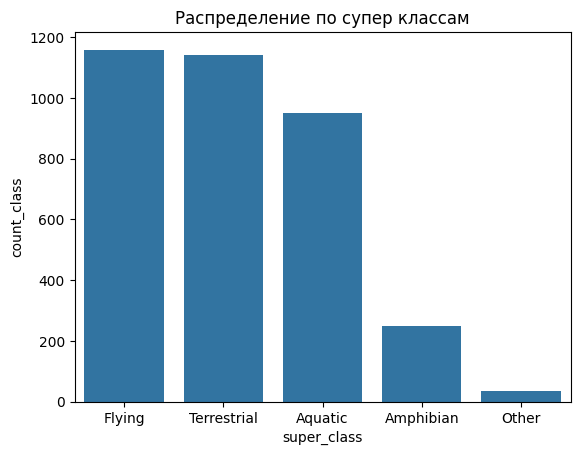

In [12]:
df_super_class = df.groupby("super_class").agg(count_class = ("image_id","count")).sort_values(by = "count_class", ascending= False)
sns.barplot(data = df_super_class, x = "super_class", y = "count_class")
plt.title("Распределение по супер классам")
plt.show()

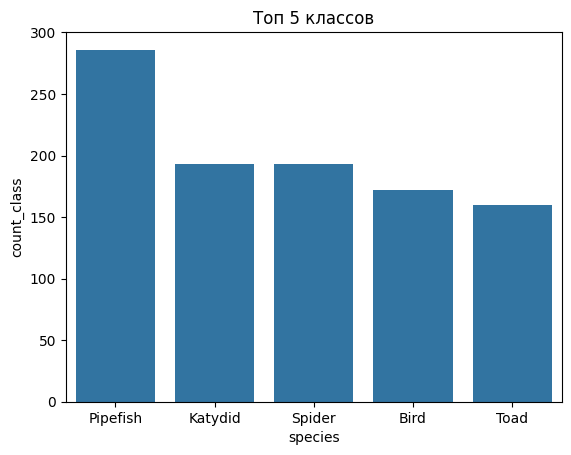

In [13]:
df_species = df.groupby("species").agg(count_class = ("image_id","count")).sort_values(by = "count_class", ascending= False)
top_df_species = df_species["count_class"].nlargest(5).reset_index()
sns.barplot(data = top_df_species, x = "species", y = "count_class")
plt.title("Топ 5 классов")
plt.show()

Исходя из распределения супер классов видно, что дисбаланс между тремя основными категориями несильный, другие категории представлены мало. В целом представлены все классы животных: наземные, водные и летающие.

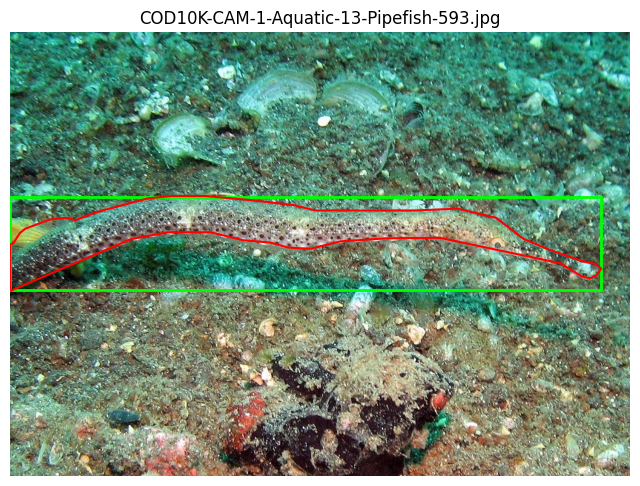

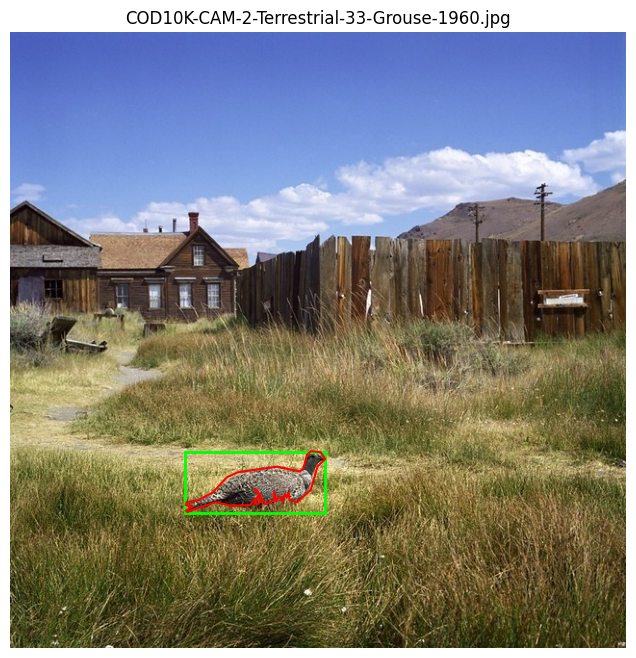

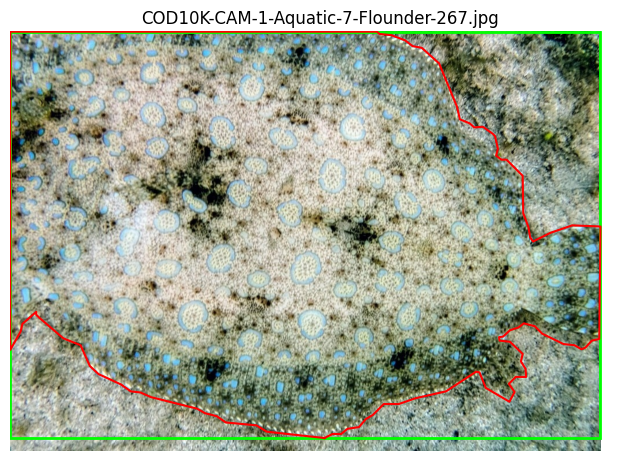

In [14]:
#Некоторые примеры: изображение + bbox + полигон
def visualize_sample(image_id, images_dir="../data/Train/Image"):
    anns = [a for a in coco_data["annotations"] if a["image_id"] == image_id]
    img_meta = image_info[image_id]
    img_path = os.path.join(images_dir, img_meta["file_name"])
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(img)
    for ann in anns:
        x, y, w, h = ann["bbox"]
        rect = plt.Rectangle((x, y), w, h, fill=False, edgecolor="lime", linewidth=2)
        ax.add_patch(rect)
        for poly in ann["segmentation"]:
            xs = poly[0::2]
            ys = poly[1::2]
            ax.plot(xs + [xs[0]], ys + [ys[0]], color="red", linewidth=1.5)
    ax.set_title(img_meta["file_name"])
    ax.axis("off")
    plt.show()

# несколько случайных примеров
sample_ids = random.sample(list(image_info.keys()), 3)
for img_id in sample_ids:
    visualize_sample(img_id)

In [62]:
def calculate_contrast(image_path: str, mask_path: str) -> float: 
    """Контраст между объектом и фоном (считается как разница средних). Считает яркость пикселей. """
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if img.shape != mask.shape:
        mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
    object_mask = mask > 0
    obj_pixels = img[object_mask]
    bg_pixels = img[~object_mask]
    if obj_pixels.size == 0 or bg_pixels.size == 0:
        return 0.0
    mean_diff = abs(np.mean(obj_pixels) - np.mean(bg_pixels))
    return float(mean_diff)

def calculate_contrast_rgb(image_path: str, mask_path: str) -> float:
    """Считает контраст в RGB."""
    img = cv2.imread(image_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    object_mask = mask > 0

    obj = img[object_mask]
    bg = img[~object_mask]

    mean_obj = np.mean(obj, axis=0)
    mean_bg = np.mean(bg, axis=0)
    contrast_rgb = np.linalg.norm(mean_obj - mean_bg)

    return contrast_rgb

def calculate_contrast_hsv(image_path: str, mask_path: str) -> float:
    """Считает контраст в HSV по каждому параметру.
        H - Цветовой тон. Измеряется в градусах от 0 до 360.
        S - Насыщенность. От 0 до 100.
        V - Яркость. От 0 до 100. Определяет насколько цвет темный.
        HSV - модель, описывающая цвет так, как его воспринимает человек.
    """
    img = cv2.imread(image_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    object_mask = mask > 0

    obj = img[object_mask]
    bg = img[~object_mask]

    h1, s1, v1 = np.mean(obj, axis=0)
    h2, s2, v2 = np.mean(bg, axis=0)
    h_diff = np.abs(h1 - h2)
    h_diff = np.minimum(h_diff, 180 - h_diff)
    s_diff = np.abs(s1 - s2)
    v_diff = np.abs(v1 - v2)

    return h_diff, s_diff, v_diff

def calculate_contrast_lab(image_path: str, mask_path: str) -> float:
    """Считает контраст в LAB.
        L - Яркость. От  до 100
        A - Цветовая ось Зеленый -- Красный. Отрицательные значения уходят в зеленый, положительные в красный.
        B - Цветовая ось Синий -- Желтый. Отрицательные значения уходят в синий, положительные в желтый.
    """
    img = cv2.imread(image_path)

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    object_mask = mask > 0
    
    obj = img_lab[object_mask]
    bg = img_lab[~object_mask]
    
    mean_obj = np.mean(obj, axis=0)
    mean_bg = np.mean(bg, axis=0)

    diff = mean_obj - mean_bg
    
    l_diff, a_diff, b_diff = float(diff[0]),float(diff[1]),float(diff[2])
    
    return np.abs(l_diff), np.abs(a_diff), np.abs(b_diff)

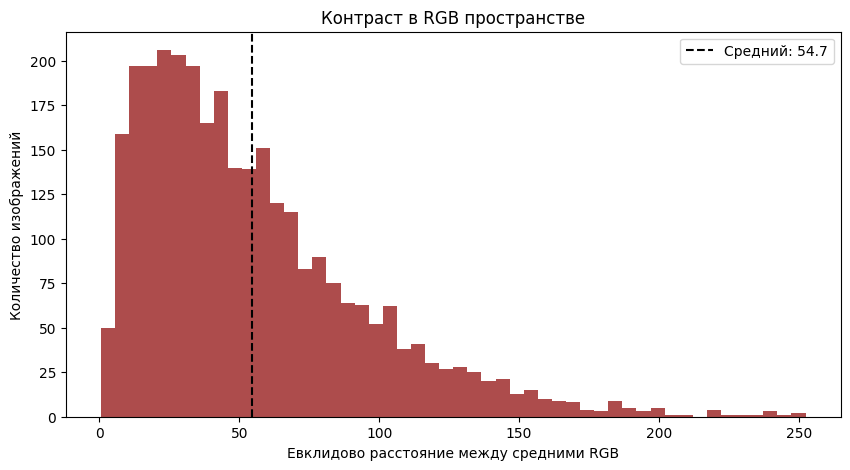

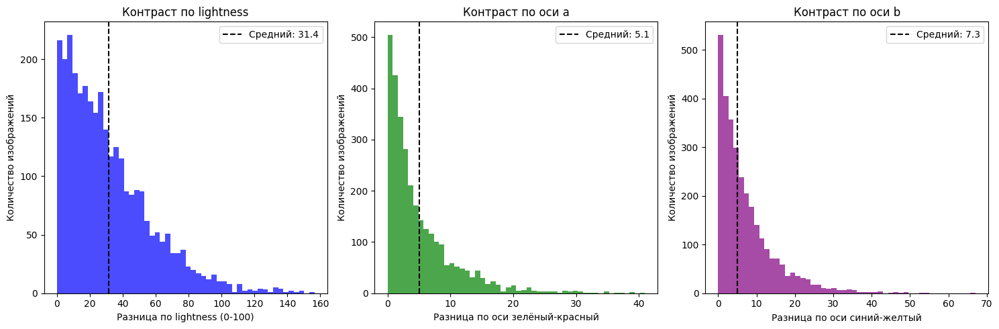

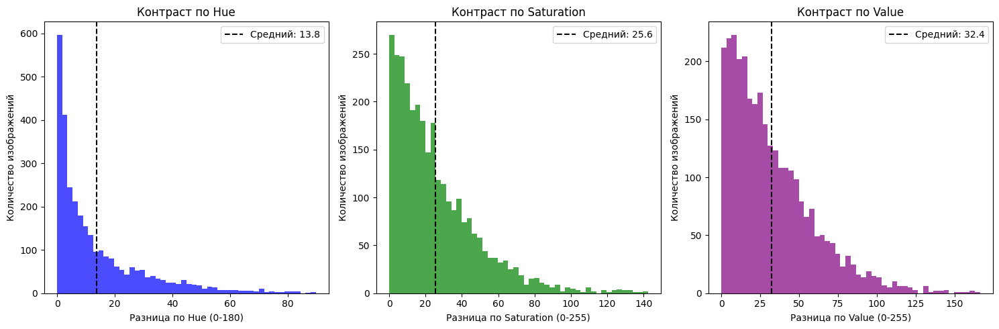

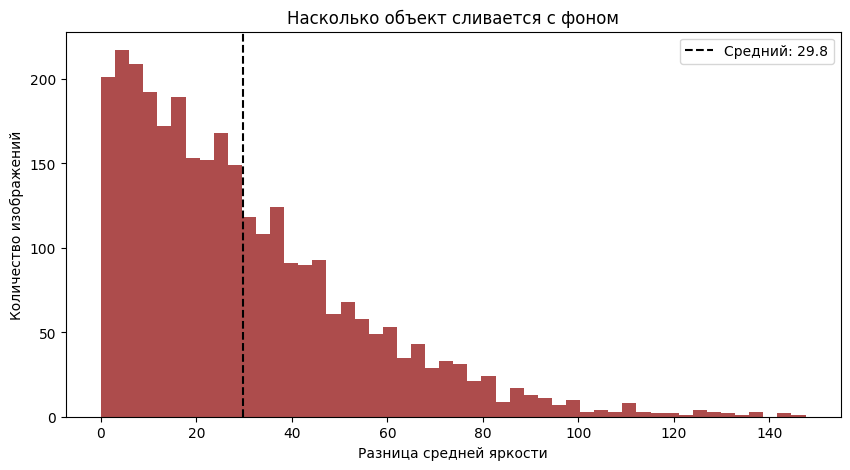

In [63]:
mask_dir = Path("../data/Train/GT_Object")
image_dir = Path("../data/Train/Image")

unique_files = df["file_name"].unique()

contrast_scores_rgb = []
l_diffs, a_diffs, b_diffs = [], [], []
h_diffs, s_diffs, v_diffs = [], [], []
contrast_scores = []
matched_files = [] 

for fname in unique_files:
    img_path = image_dir / fname
    mask_path = mask_dir / (Path(fname).stem + ".png")

    if not img_path.exists() or not mask_path.exists():
        print(f"Нет пары для {fname}")
        continue

    img_path, mask_path = str(img_path), str(mask_path)

    rgb_score = calculate_contrast_rgb(img_path, mask_path)
    h, s, v = calculate_contrast_hsv(img_path, mask_path)
    l,a,b = calculate_contrast_lab(img_path, mask_path)
    mean_diff = calculate_contrast(img_path, mask_path)

    row = {
        "file_name" : fname,
        "rgb_score": rgb_score,
        "h_score": h,
        "s_score": s,
        "v_score": v,
        "l_score" : l,
        "a_score" : a,
        "b_score" : b,
        "grayscale_score": mean_diff
    }

    contrast_scores.append(mean_diff)
    contrast_scores_rgb.append(rgb_score)
    h_diffs.append(h); s_diffs.append(s); v_diffs.append(v)
    l_diffs.append(l); a_diffs.append(a); b_diffs.append(b)
    matched_files.append(row)

# 1. RGB
plt.figure(figsize=(10, 5))
plt.hist(contrast_scores_rgb, bins=50, color="darkred", alpha=0.7)
plt.axvline(np.mean(contrast_scores_rgb), color="black", linestyle="--", 
            label=f"Средний: {np.nanmean(contrast_scores_rgb):.1f}")
plt.xlabel("Евклидово расстояние между средними RGB")
plt.ylabel("Количество изображений")
plt.title("Контраст в RGB пространстве")
plt.legend()
plt.show()

# 2. LAB (три канала)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].hist(l_diffs, bins=50, color="blue", alpha=0.7)
axes[0].axvline(np.mean(l_diffs), color="black", linestyle="--", 
                label=f"Средний: {np.nanmean(l_diffs):.1f}")
axes[0].set_xlabel("Разница по lightness (0-100)")
axes[0].set_ylabel("Количество изображений")
axes[0].set_title("Контраст по lightness")
axes[0].legend()

axes[1].hist(a_diffs, bins=50, color="green", alpha=0.7)
axes[1].axvline(np.mean(a_diffs), color="black", linestyle="--", 
                label=f"Средний: {np.nanmean(a_diffs):.1f}")
axes[1].set_xlabel("Разница по оси зелёный-красный")
axes[1].set_ylabel("Количество изображений")
axes[1].set_title("Контраст по оси a")
axes[1].legend()

axes[2].hist(b_diffs, bins=50, color="purple", alpha=0.7)
axes[2].axvline(np.mean(a_diffs), color="black", linestyle="--", 
                label=f"Средний: {np.nanmean(b_diffs):.1f}")
axes[2].set_xlabel("Разница по оси синий-желтый")
axes[2].set_ylabel("Количество изображений")
axes[2].set_title("Контраст по оси b")
axes[2].legend()

plt.tight_layout()
plt.show()

# 3. HSV
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].hist(h_diffs, bins=50, color="blue", alpha=0.7)
axes[0].axvline(np.mean(h_diffs), color="black", linestyle="--", 
                label=f"Средний: {np.nanmean(h_diffs):.1f}")
axes[0].set_xlabel("Разница по Hue (0-180)")
axes[0].set_ylabel("Количество изображений")
axes[0].set_title("Контраст по Hue")
axes[0].legend()

axes[1].hist(s_diffs, bins=50, color="green", alpha=0.7)
axes[1].axvline(np.mean(s_diffs), color="black", linestyle="--", 
                label=f"Средний: {np.nanmean(s_diffs):.1f}")
axes[1].set_xlabel("Разница по Saturation (0-255)")
axes[1].set_ylabel("Количество изображений")
axes[1].set_title("Контраст по Saturation")
axes[1].legend()

axes[2].hist(v_diffs, bins=50, color="purple", alpha=0.7)
axes[2].axvline(np.mean(v_diffs), color="black", linestyle="--", 
                label=f"Средний: {np.nanmean(v_diffs):.1f}")
axes[2].set_xlabel("Разница по Value (0-255)")
axes[2].set_ylabel("Количество изображений")
axes[2].set_title("Контраст по Value")
axes[2].legend()

plt.tight_layout()
plt.show()

# 4. grayscale
plt.figure(figsize=(10, 5))
plt.hist(contrast_scores, bins=50, color="darkred", alpha=0.7)
plt.axvline(np.mean(contrast_scores), color="black", linestyle="--", label=f"Средний: {np.nanmean(contrast_scores):.1f}")
plt.xlabel("Разница средней яркости")
plt.ylabel("Количество изображений")
plt.title("Насколько объект сливается с фоном")
plt.legend()
plt.show()

In [17]:
img = cv2.imread("../data/Train/Image/COD10K-CAM-1-Aquatic-1-BatFish-1.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
mask = cv2.imread("../data/Train/GT_Object/COD10K-CAM-1-Aquatic-1-BatFish-1.png", cv2.IMREAD_GRAYSCALE)
object_mask = mask > 0
obj = img[object_mask]
bg = img[~object_mask]
mean_obj = np.mean(obj, axis=0)
mean_bg = np.mean(bg, axis=0)
print(f"Средние значения обьекта в RGB: {mean_obj}")
print(f"Средние значение фона в RGB: {mean_bg}")

Средние значения обьекта в RGB: [68.53186224 47.81224995 99.5056094 ]
Средние значение фона в RGB: [ 75.89845195  55.94622141 111.92221965]


In [18]:
diff = np.abs(mean_obj - mean_bg)
print(f"Абсолютаня средняя разница по всем изображениям в RGB {diff}")

Абсолютаня средняя разница по всем изображениям в RGB [ 7.36658971  8.13397146 12.41661024]


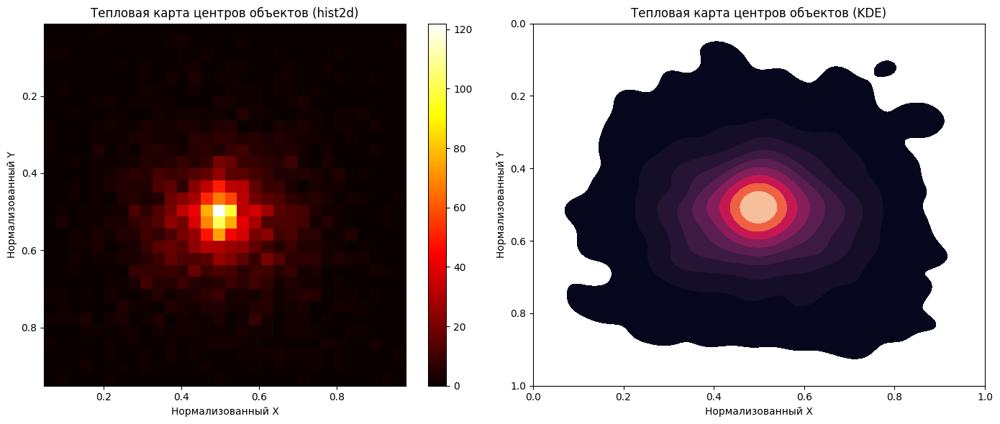

In [19]:
df['bbox_cx'] = (df['bbox_x'] + df['bbox_width'] / 2) / df['img_width']
df['bbox_cy'] = (df['bbox_y'] + df['bbox_height'] / 2) / df['img_height']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
h = axes[0].hist2d(df['bbox_cx'], df['bbox_cy'], bins=30, cmap='hot')
axes[0].set_title('Тепловая карта центров объектов (hist2d)')
axes[0].set_xlabel('Нормализованный X')
axes[0].set_ylabel('Нормализованный Y')
axes[0].invert_yaxis() 
plt.colorbar(h[3], ax=axes[0])

sns.kdeplot(x=df['bbox_cx'], y=df['bbox_cy'], cmap='rocket', fill=True, thresh=0.02, ax=axes[1])
axes[1].set_title('Тепловая карта центров объектов (KDE)')
axes[1].set_xlabel('Нормализованный X')
axes[1].set_ylabel('Нормализованный Y')
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1)
axes[1].set_ylim(1, 0)

plt.tight_layout()
plt.show()

Из тепловой карты видно, что объекты в осномно сосредоточены в центре ихображения. Что может стать причиной переобучения или плохой сегментации, если объект расположен с краю. 

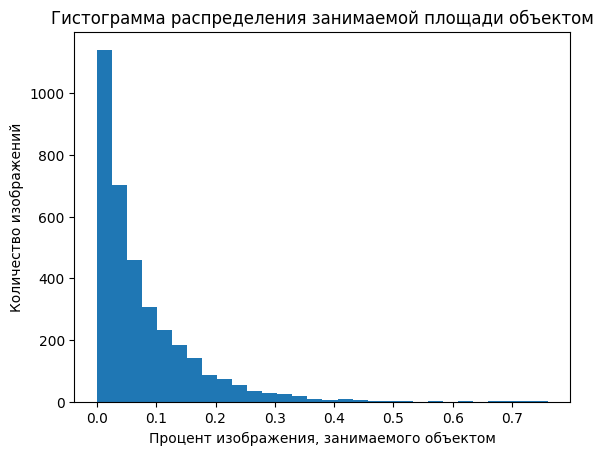

In [20]:
plt.hist(df["obj_ratio"],bins = 30)
plt.title("Гистограмма распределения занимаемой площади объектом")
plt.xlabel("Процент изображения, занимаемого объектом")
plt.ylabel("Количество изображений")
plt.show()

В основном преобладают изображения, где объект занимает малую часть изображения

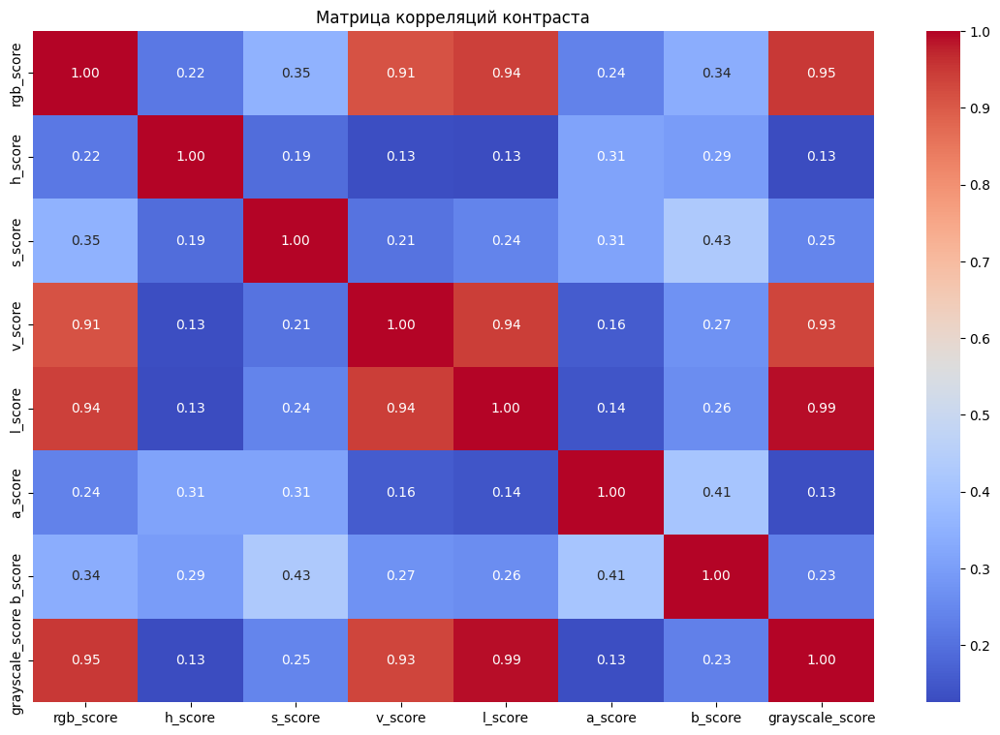

In [68]:
df_contrast = pd.DataFrame(matched_files)
df_contrast = pd.merge(df_contrast, df, on = "file_name", how = "right")
corr_contrast = df_contrast[["rgb_score","h_score","s_score","v_score","l_score","a_score","b_score","grayscale_score"]].corr(method="spearman")
plt.figure(figsize = (14,9))
sns.heatmap(corr_contrast, annot = True, cmap = "coolwarm", fmt = ".2f")

plt.title("Матрица корреляций контраста")
plt.show()

In [69]:
df_contrast[["rgb_score","h_score","s_score","v_score","l_score","a_score","b_score","grayscale_score"]].describe()

,rgb_score,h_score,s_score,v_score,l_score,a_score,b_score,grayscale_score
count,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000
mean,54.315733,13.846249,25.706572,32.143884,31.117158,5.116738,7.406391,29.554174
std,39.479195,15.697924,22.959382,26.377596,25.294710,5.475954,7.557555,24.026707
min,0.608073,0.000000,0.000000,0.002999,0.001511,0.000000,0.000000,0.016012
25%,25.046799,2.466034,8.603748,11.478903,11.329018,1.308052,2.117043,10.840807
50%,44.713210,7.666546,19.414040,25.641742,25.331894,3.261372,5.059128,24.020624
75%,73.816889,19.752975,36.691693,46.171405,44.481682,7.170658,10.052198,42.058864
max,252.351820,89.661274,142.383602,166.291207,156.443665,40.955940,67.051102,147.587771


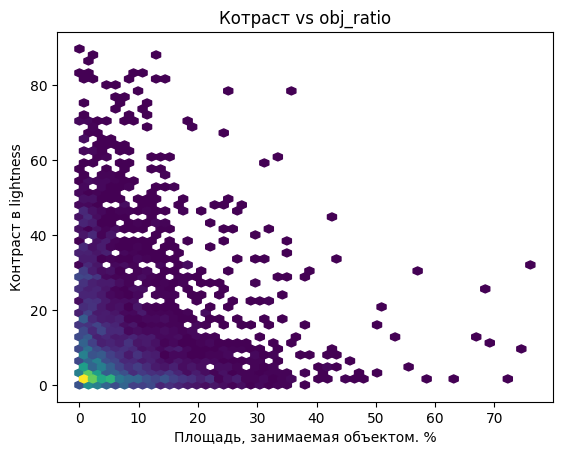

In [ ]:
df_contrast = pd.DataFrame(matched_files)
df_contrast = pd.merge(df_contrast, df, on = "file_name", how = "right")
plt.hexbin(x = df_contrast["obj_ratio"]*100,y = df_contrast["h_score"], gridsize=50, cmap='viridis', mincnt=1)
plt.xlabel("Площадь, занимаемая объектом. %")
plt.ylabel("Контраст в lightness")
plt.title("Котраст vs obj_ratio")
plt.show()

Из графика scatter видно, что большинство объектов одновременно маленькие и слабо различимы в контрасте.

Выведем самые сложные картинки по контрасту rgb

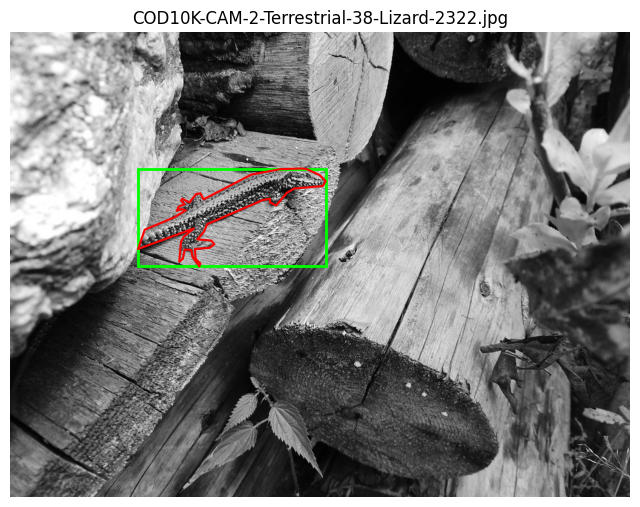

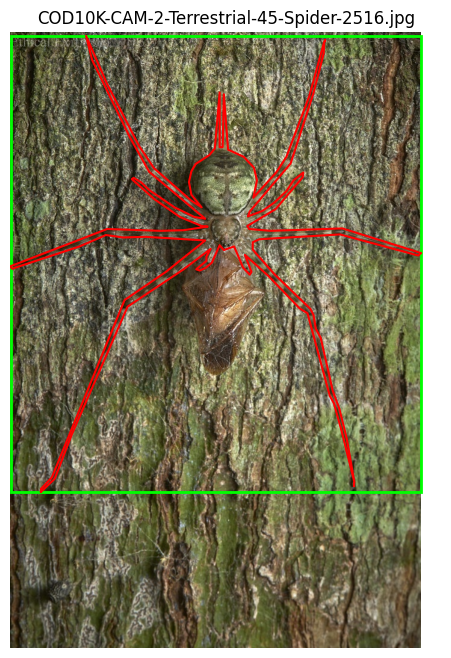

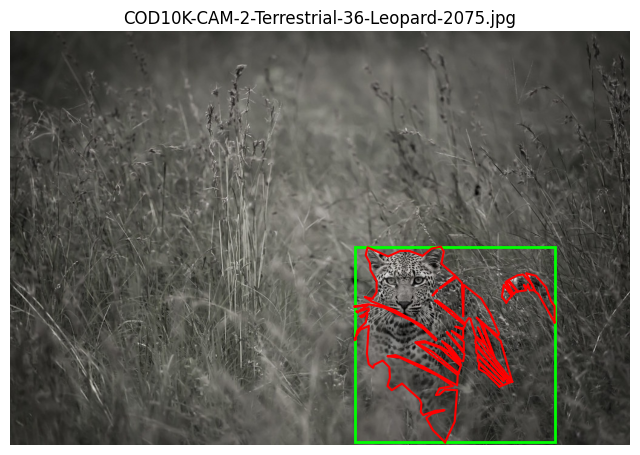

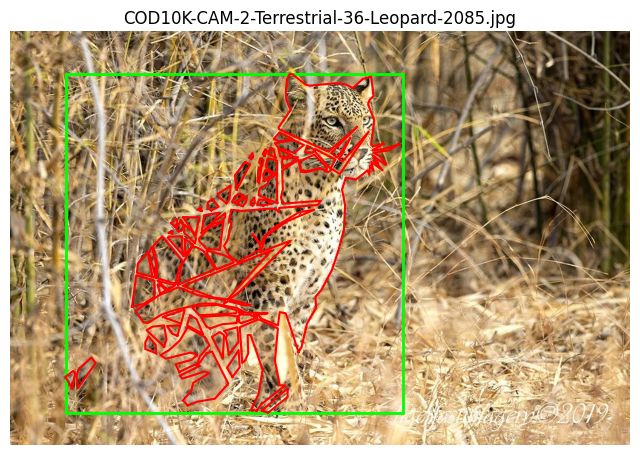

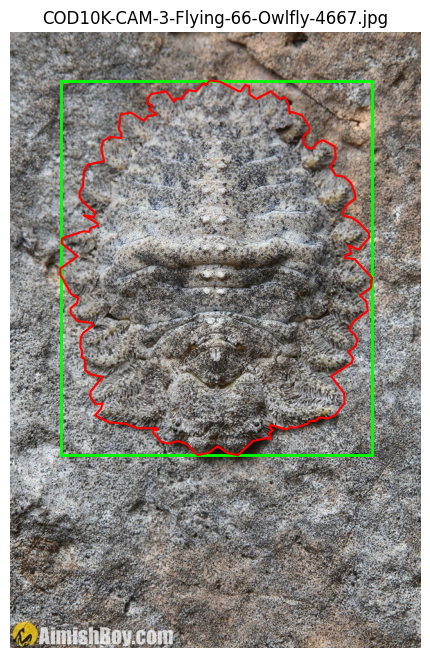

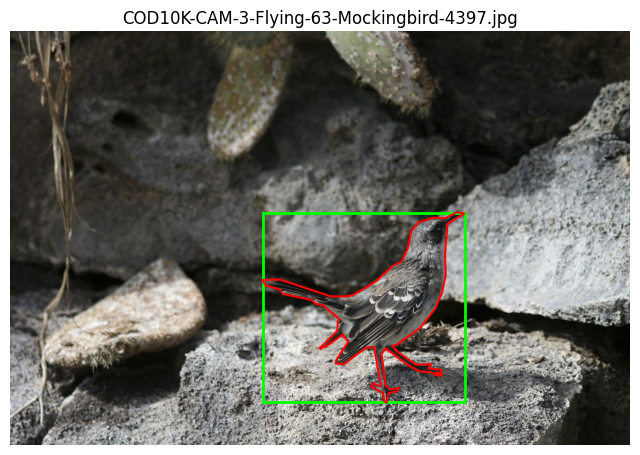

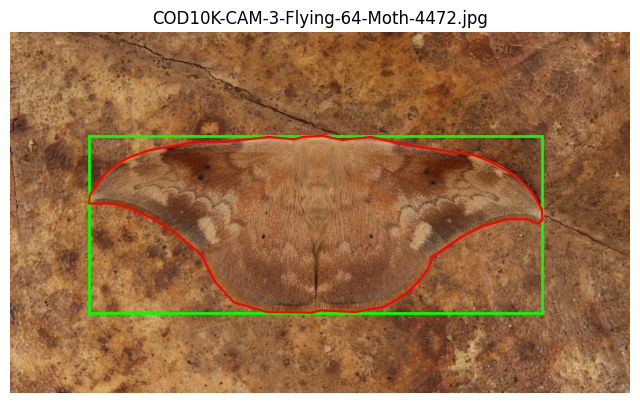

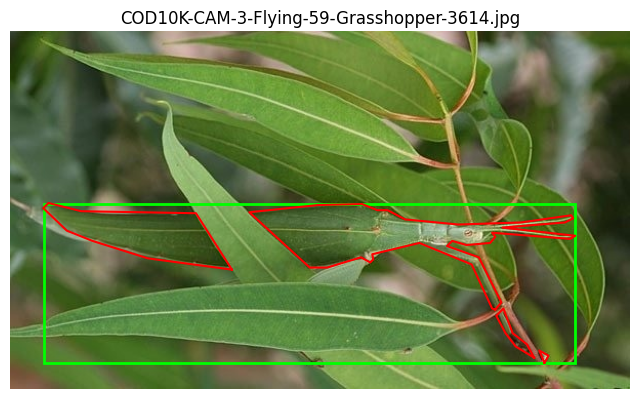

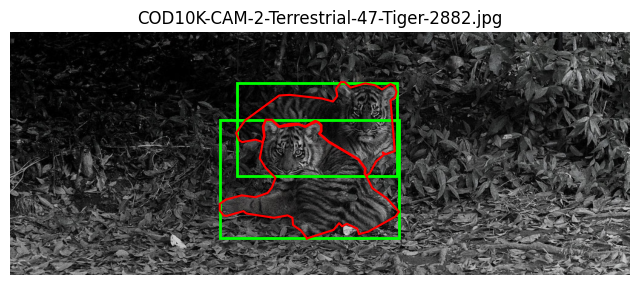

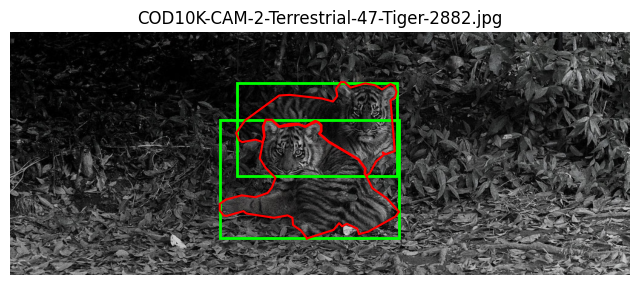

In [22]:
top_hardest = list(df_contrast.sort_values(by = "rgb_score").head(10)["image_id"])
for i in top_hardest:
    visualize_sample(i)

Видно, что некоторые фотографии сделаны в оттенках серого, такие фотографии слаборазличимы для LAB, поэтому посмотрим на score в grayscale, у этих же фотографий 

In [23]:
df_contrast.sort_values(by = "rgb_score").head(10)

,file_name,rgb_score,h_score,s_score,v_score,l_score,a_score,b_score,grayscale_score,image_id,...,img_width,img_height,img_area,obj_ratio,bbox_aspect_ratio,num_polygons,super_class,species,bbox_cx,bbox_cy
1684,COD10K-CAM-2-Terrestrial-38-Lizard-2322.jpg,0.608073,0.000000,0.000000,0.351071,-0.008415,0.000000,0.000000,0.351071,1404,...,1024,768,786432,0.017054,1.937500,1,Terrestrial,Lizard,0.357422,0.398438
1817,COD10K-CAM-2-Terrestrial-45-Spider-2516.jpg,1.628035,1.538857,0.703865,0.821076,-1.240700,0.944771,0.944771,0.894804,1522,...,683,1024,699392,0.049780,0.899736,3,Terrestrial,Spider,0.500732,0.375977
1505,COD10K-CAM-2-Terrestrial-36-Leopard-2075.jpg,1.994782,2.983330,2.042902,0.241192,-0.668571,0.084999,0.084999,0.173404,1248,...,1024,683,699392,0.057906,1.024768,18,Terrestrial,Leopard,0.717285,0.756223
1511,COD10K-CAM-2-Terrestrial-36-Leopard-2085.jpg,2.162331,0.413119,0.057468,0.591304,-0.572388,0.329987,0.329987,0.184478,1254,...,1024,683,699392,0.127995,0.994633,64,Terrestrial,Leopard,0.361328,0.511713
3241,COD10K-CAM-3-Flying-66-Owlfly-4667.jpg,2.257486,1.101773,3.895362,1.105496,-0.012665,-0.491821,-0.491821,0.370345,2782,...,640,960,614400,0.339551,0.831904,1,Flying,Owlfly,0.502344,0.382812
3070,COD10K-CAM-3-Flying-63-Mockingbird-4397.jpg,2.265667,1.464879,13.262248,0.164018,1.869293,-0.013855,-0.013855,0.481174,2626,...,1024,683,699392,0.038396,1.067093,2,Flying,Mockingbird,0.570312,0.666911
3114,COD10K-CAM-3-Flying-64-Moth-4472.jpg,2.365465,0.689480,1.531942,0.914096,-1.477623,0.747971,0.747971,1.210044,2670,...,1023,596,609708,0.228783,2.570447,1,Flying,Moth,0.492669,0.532718
2587,COD10K-CAM-3-Flying-59-Grasshopper-3614.jpg,2.733714,0.818650,1.088698,2.741269,-1.778923,-0.204651,-0.204651,1.283618,2184,...,605,349,211145,0.073656,3.341935,4,Flying,Grasshopper,0.482645,0.703438
2044,COD10K-CAM-2-Terrestrial-47-Tiger-2882.jpg,2.884139,2.234375,0.200360,1.654079,1.641052,0.136368,0.136368,1.663303,1737,...,1024,402,411648,0.071000,1.512821,1,Terrestrial,Tiger,0.482910,0.605721
2045,COD10K-CAM-2-Terrestrial-47-Tiger-2882.jpg,2.884139,2.234375,0.200360,1.654079,1.641052,0.136368,0.136368,1.663303,1737,...,1024,402,411648,0.044973,1.714286,1,Terrestrial,Tiger,0.494141,0.400498


In [24]:
def compute_texture_zones(image_path: str, mask_path: str,
                           ring_scale: float = 0.3,
                           ring_min: int = 5,
                           ring_max: int = 80,
                           local_ksize: int = 5):
    """
    Считает среднюю локальную дисперсию (текстуру) в трёх зонах:
    - object    : сам объект (по маске)
    - local_bg  : кольцо вокруг объекта, ширина масштабируется под размер объекта
    - global_bg : всё, что осталось (дальний фон)

    ring_scale - доля от sqrt(bbox_area) объекта, определяющая ширину кольца
    ring_min/ring_max - защита от слишком узкого/слишком широкого кольца
    local_ksize - размер окна локальной дисперсии текстуры
    """
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if img is None or mask is None:
        return None
    if img.shape != mask.shape:
        mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

    object_mask = mask > 0
    if object_mask.sum() == 0:
        return None

    y_idx, x_idx = np.where(object_mask)
    bbox_h = y_idx.max() - y_idx.min() + 1
    bbox_w = x_idx.max() - x_idx.min() + 1

    ring_size = int(np.sqrt(bbox_h * bbox_w) * ring_scale)
    ring_size = int(np.clip(ring_size, ring_min, ring_max))
    if ring_size % 2 == 0:
        ring_size += 1  # нечётный размер ядра для симметричной дилатации

    obj_uint8 = object_mask.astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ring_size, ring_size))
    dilated = cv2.dilate(obj_uint8, kernel, iterations=1).astype(bool)

    local_bg_mask = dilated & ~object_mask
    global_bg_mask = ~dilated

    gray = img.astype(np.float32)
    mean = cv2.blur(gray, (local_ksize, local_ksize))
    mean_sq = cv2.blur(gray ** 2, (local_ksize, local_ksize))
    local_var_map = np.clip(mean_sq - mean ** 2, 0, None)

    def safe_mean(m):
        vals = local_var_map[m]
        return float(np.mean(vals)) if vals.size > 0 else np.nan

    return {
        "object_var": safe_mean(object_mask),
        "local_bg_var": safe_mean(local_bg_mask),
        "global_bg_var": safe_mean(global_bg_mask),
        "ring_size_used": ring_size, 
    }

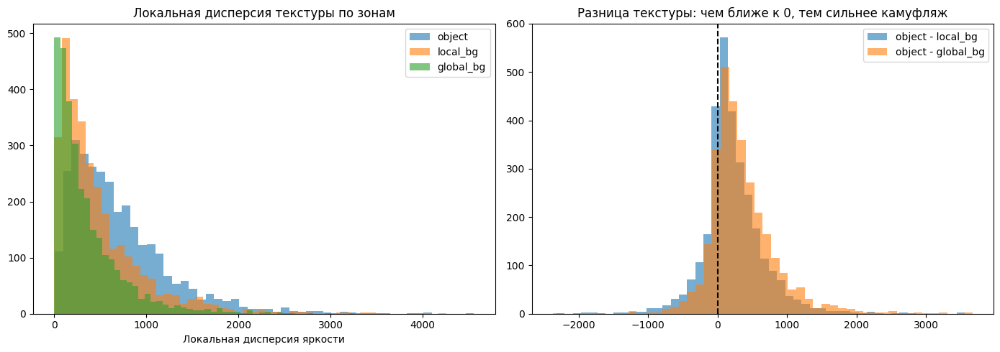

In [25]:
image_dir = Path("../data/Train/Image")
mask_dir = Path("../data/Train/GT_Object")

texture_rows = []
for fname in df["file_name"].unique():
    img_path = image_dir / fname
    mask_path = mask_dir / (Path(fname).stem + ".png")
    if not img_path.exists() or not mask_path.exists():
        continue
    res = compute_texture_zones(str(img_path), str(mask_path))
    if res is None:
        continue
    res["file_name"] = fname
    texture_rows.append(res)

df_texture = pd.DataFrame(texture_rows)
df_texture["obj_vs_local_diff"] = df_texture["object_var"] - df_texture["local_bg_var"]
df_texture["obj_vs_global_diff"] = df_texture["object_var"] - df_texture["global_bg_var"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_texture["object_var"], bins=50, alpha=0.6, label="object")
axes[0].hist(df_texture["local_bg_var"], bins=50, alpha=0.6, label="local_bg")
axes[0].hist(df_texture["global_bg_var"], bins=50, alpha=0.6, label="global_bg")
axes[0].set_title("Локальная дисперсия текстуры по зонам")
axes[0].set_xlabel("Локальная дисперсия яркости")
axes[0].legend()

axes[1].hist(df_texture["obj_vs_local_diff"], bins=50, alpha=0.6, label="object - local_bg")
axes[1].hist(df_texture["obj_vs_global_diff"], bins=50, alpha=0.6, label="object - global_bg")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Разница текстуры: чем ближе к 0, тем сильнее камуфляж")
axes[1].legend()

plt.tight_layout()
plt.show()

In [26]:
def GLCM(image_path: str, mask_path: str, distances: list = None, angles: list = None): 
    """
    image_path - Путь к изображению
    mask_path - Путь к маске
    distances - Расстояние между пикселями
    andles - Угол наклона, по которому высчитываются пиксели

    На выходе получаем две матрицы для объекта и для фона соответственно
    """
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if img is None or mask is None:
        return None
    if img.shape != mask.shape:
        mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

    object_mask = mask > 0
    if object_mask.sum() == 0:
        return None

    bg_mask  = ~object_mask 

    shifted_img = img.astype(np.uint16) + 1 # Сдвиг на 1, чтобы можно было применять маску

    masked_obj = np.where(object_mask, shifted_img, 0)
    masked_bg = np.where(bg_mask, shifted_img, 0)

    glcm_obj = graycomatrix(masked_obj, 
                        distances=distances, 
                        angles=angles, 
                        levels=257,  # +1 уровень для технического нуля
                        symmetric=True, 
                        normed=False) 
    glcm_clean_obj = glcm_obj[1:, 1:, :, :]
    glcm_sums_obj = np.sum(glcm_clean_obj, axis=(0, 1), keepdims=True)
    
    glcm_norm_obj= np.where(glcm_sums_obj > 0, glcm_clean_obj / glcm_sums_obj, 0.0)

    glcm_bg = graycomatrix(masked_bg, 
                            distances=distances, 
                            angles=angles, 
                            levels=257,  # +1 уровень для технического нуля
                            symmetric=True, 
                            normed=False) 
    glcm_clean_bg = glcm_bg[1:, 1:, :, :]
    glcm_sums_bg = np.sum(glcm_clean_bg, axis=(0, 1), keepdims=True)
        
    glcm_norm_bg= np.where(glcm_sums_bg > 0, glcm_clean_bg / glcm_sums_bg, 0.0)

    
    return glcm_norm_obj,glcm_norm_bg



In [ ]:
def BoundaryRatio(mask_path):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return None

    # делаем бинарную uint8-маску
    _, binary = cv2.threshold(mask, 0, 255, cv2.THRESH_BINARY)

    if cv2.countNonZero(binary) == 0:
        return None

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return None

    # если объектов несколько — суммируем площадь и периметр
    area_px = sum(cv2.contourArea(c) for c in contours)
    if area_px <= 0:
        return None

    perimeter_px = sum(cv2.arcLength(c, True) for c in contours)

    ratio = perimeter_px / np.sqrt(area_px)
    return ratio
mask_dir = Path("../data/Train/GT_Object")
b_ratio = []
for fname in df["file_name"].unique():
    mask_path = mask_dir / (Path(fname).stem + ".png")
    if  not mask_path.exists():
        continue
    ratio = BoundaryRatio(mask_path)
    rows = {
        "file_name": fname,
        "b_ratio": ratio
    }
    b_ratio.append(rows)
df_b_ratio = pd.DataFrame(b_ratio)

In [13]:
df_b_ratio.describe()

,b_ratio
count,3040.000000
mean,11.987686
std,8.342570
min,3.866972
25%,6.997195
50%,9.705069
75%,14.453318
max,183.956744


BoundaryRatio достаточно высокий, что означает что границы обьектов довольно сложные

In [2]:
image_dir = Path("../data/Train/Image")
mask_dir = Path("../data/Train/GT_Object")

glcm = []
for fname in df["file_name"].unique():
    img_path = image_dir / fname
    mask_path = mask_dir / (Path(fname).stem + ".png")
    if not img_path.exists() or not mask_path.exists():
        continue
    matrix_obj,matrix_bg = GLCM(str(img_path), str(mask_path), [1, 2],[0, np.pi/4, np.pi/2, 3*np.pi/4] )

    contrast_obj = graycoprops(matrix_obj, 'contrast')     # shape (len(distances), len(angles))
    homogeneity_obj = graycoprops(matrix_obj, 'homogeneity')
    energy_obj = graycoprops(matrix_obj, 'energy')
    correlation_obj = graycoprops(matrix_obj, 'correlation')

    contrast_bg = graycoprops(matrix_bg, 'contrast')     # shape (len(distances), len(angles))
    homogeneity_bg = graycoprops(matrix_bg, 'homogeneity')
    energy_bg = graycoprops(matrix_bg, 'energy')
    correlation_bg = graycoprops(matrix_bg, 'correlation')

    rows = {
        "file_name": fname,
        "contrast": contrast_bg - contrast_obj,
        "homogeneity": homogeneity_bg - homogeneity_obj,
        "energy": energy_bg - energy_obj,
        "correlation": correlation_bg - correlation_obj     
    }

    glcm.append(rows)


NameError: name 'Path' is not defined

In [28]:
df_glcm = pd.DataFrame(glcm)
df_glcm

,file_name,contrast,homogeneity,energy,correlation
0,COD10K-CAM-1-Aquatic-1-BatFish-8.jpg,"[[-67.66834534649297, -61.96506609518633, -0.8...","[[0.013574275781804063, 0.010819113764188995, ...","[[0.0013358754321565157, 0.0009513743809096194...","[[0.00522407093339361, -0.008659041148448066, ..."
1,COD10K-CAM-1-Aquatic-1-BatFish-9.jpg,"[[174.00044939398776, 180.39966345398489, 129....","[[-0.004891840726235809, -0.005122933292991072...","[[-0.0017728263348460466, -0.00177040270891617...","[[0.10696441801205303, 0.17741002939381456, 0...."
2,COD10K-CAM-1-Aquatic-2-ClownFish-12.jpg,"[[553.5573418669836, 810.621360607503, 403.354...","[[-0.022216015725488508, -0.03856255393593919,...","[[-0.006874614236610066, -0.00772731790914267,...","[[-0.13024128998796392, -0.19130994293062242, ..."
3,COD10K-CAM-1-Aquatic-2-ClownFish-14.jpg,"[[-11.030491567663944, -7.465897438889385, -8....","[[0.05982530202694264, 0.022350117660054847, 0...","[[-0.0020809085428648184, -0.00342298167082984...","[[0.00466433286648793, 0.00501820114323237, 0...."
4,COD10K-CAM-1-Aquatic-2-ClownFish-16.jpg,"[[-249.22583318224838, -85.36800453044361, -10...","[[-0.0065748177419002185, -0.00348423688829155...","[[-0.01100319282276158, -0.01050084769653704, ...","[[0.05245295292170027, 0.03141576835389537, 0...."
...,...,...,...,...,...
3035,COD10K-CAM-5-Other-69-Other-5065.jpg,"[[-776.4111038891033, -1309.6865208622573, -67...","[[-0.008748815474282502, -0.009932716417795438...","[[0.0002156098796221896, 1.936606299997659e-05...","[[-0.10010239593024062, -0.12607240691834753, ..."
3036,COD10K-CAM-5-Other-69-Other-5066.jpg,"[[382.4576390819599, 671.7666485456328, 501.11...","[[-0.07128455187543538, -0.05043343219661556, ...","[[-0.005801172558016272, -0.004886662878542244...","[[-0.0749772733738644, -0.13215437707927002, -..."
3037,COD10K-CAM-1-Aquatic-1-BatFish-1.jpg,"[[210.78503078290126, 323.71437984948057, 201....","[[-0.08792707251792252, -0.06203736154089605, ...","[[-0.0040492852871520674, -0.00320829201612685...","[[-0.08098596819737214, -0.1302525362638438, -..."
3038,COD10K-CAM-1-Aquatic-1-BatFish-3.jpg,"[[-131.48844789431078, -194.07371802713726, -1...","[[0.048381221765972815, 0.030026273858900887, ...","[[0.006389393596993573, 0.004914831439176322, ...","[[0.14927029786431611, 0.21774951274432996, 0...."


In [29]:
sample = df_glcm["contrast"].iloc[0]
sample

array([[-67.66834535, -61.9650661 ,  -0.86440392, -32.41805021],
       [-89.87219785, -61.9650661 ,  16.90332861, -32.41805021]])

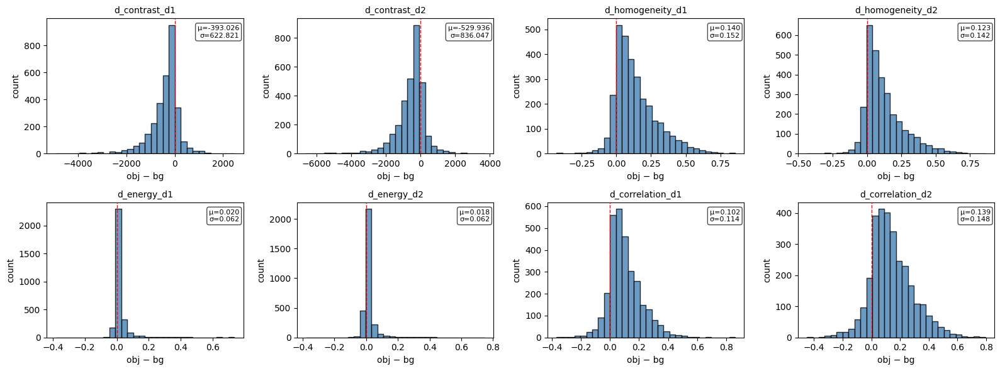

In [30]:
def expand_glcm_lists_by_dist(df: pd.DataFrame,
                              prefix: str = "",
                              n_distances: int = 2,
                              n_angles: int = 4) -> pd.DataFrame:
    features = ["contrast", "homogeneity", "energy", "correlation"]
    df = df.loc[:, ~df.columns.duplicated()].copy()
    df = df.drop_duplicates(subset="file_name").reset_index(drop=True)

    out = pd.DataFrame({"file_name": df["file_name"].values})
    n = n_distances * n_angles

    for feat in features:
        cleaned = [np.asarray(x, dtype=float).ravel() for x in df[feat].values]
        lengths = {len(c) for c in cleaned}
        if lengths != {n}:
            raise ValueError(f"{feat}: ожидали длину {n}, получили {lengths}")

        arr = np.vstack(cleaned)              # (rows, 8)
        arr = arr.reshape(-1, n_distances, n_angles)   # (rows, d, a)
        arr_mean = arr.mean(axis=2)           # усреднили по углам -> (rows, d)

        for di in range(n_distances):
            out[f"{prefix}_{feat}_d{di+1}"] = arr_mean[:, di]

    return out

def plot_all_diffs(df_diff: pd.DataFrame, bins: int = 30):
    """
    Строит сетку 3x4 гистограмм — по одной на каждый разностный признак.
    df_diff должен содержать колонки d_<feature>_d<k> и file_name.
    """
    cols = [c for c in df_diff.columns if c != "file_name"]
    n = len(cols)
    ncols = 4
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    axes = axes.flatten()

    for ax, col in zip(axes, cols):
        vals = df_diff[col].dropna().values
        ax.hist(vals, bins=bins, color="steelblue", edgecolor="black", alpha=0.8)
        ax.axvline(0, color="red", linestyle="--", linewidth=1)
        ax.set_title(col, fontsize=10)
        ax.set_xlabel("obj − bg")
        ax.set_ylabel("count")
        # полезно видеть среднее и std прямо на графике
        ax.text(0.98, 0.95,
                f"μ={vals.mean():.3f}\nσ={vals.std():.3f}",
                transform=ax.transAxes, ha="right", va="top",
                fontsize=8,
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.7))

    # скрыть пустые оси, если 12 не делится на 4
    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
df_glcm = expand_glcm_lists_by_dist(df_glcm, prefix = "d")
plot_all_diffs(df_glcm)

# Проверка train

In [33]:
def _load(json_path):
    with open(json_path, encoding="utf-8") as f:
        return json.load(f)


def polygon_area(coords):
    """Площадь полигона (shoelace). coords = [x1,y1,x2,y2,...]."""
    n = len(coords) // 2
    if n < 3:
        return 0.0
    s = 0.0
    for i in range(n):
        x1, y1 = coords[2 * i], coords[2 * i + 1]
        x2, y2 = coords[2 * ((i + 1) % n)], coords[2 * ((i + 1) % n) + 1]
        s += x1 * y2 - x2 * y1
    return abs(s) / 2.0


def bbox_area(bbox):
    return max(0.0, bbox[2]) * max(0.0, bbox[3])


def _fmt_counter(counter, top=None, total=None):
    items = counter.most_common(top) if top else counter.most_common()
    if total is None:
        total = sum(counter.values()) or 1
    return "\n".join(
        f"    {k}: {v} ({100.0 * v / total:.2f}%)" for k, v in items
    )


# ==========================
# 1. Общая сводка
# ==========================
def eda_summary(json_path, split_name=None):
    """Общая сводка по датасету: число изображений/аннотаций/категорий."""
    split_name = split_name or os.path.basename(json_path)
    coco = _load(json_path)

    images      = coco.get("images", [])
    annotations = coco.get("annotations", [])
    categories  = coco.get("categories", [])

    print(f"\n{'=' * 60}")
    print(f"  Сводка: {split_name}")
    print(f"{'=' * 60}")
    print(f"  Изображений:  {len(images)}")
    print(f"  Аннотаций:    {len(annotations)}")
    print(f"  Категорий:    {len(categories)}")

    if images:
        ws = [im["width"]  for im in images]
        hs = [im["height"] for im in images]
        print(f"  Размеры изображений:")
        print(f"    W: min={min(ws)} max={max(ws)} avg={sum(ws)/len(ws):.1f}")
        print(f"    H: min={min(hs)} max={max(hs)} avg={sum(hs)/len(hs):.1f}")

    print(f"  Категории:")
    for c in categories:
        print(f"    id={c.get('id')}  name={c.get('name')}")

    if annotations:
        avg = len(annotations) / len(images) if images else 0
        print(f"  Объектов на изображение (avg): {avg:.2f}")

    return coco


# ==========================
# 2. Распределение по классам
# ==========================
def eda_class_distribution(coco, split_name="train", top=None):
    """Сколько объектов в каждом классе + доля."""
    print(f"\n--- Распределение по классам: {split_name} ---")

    id_to_name = {c["id"]: c.get("name", str(c["id"])) for c in coco.get("categories", [])}
    counter = Counter(a["category_id"] for a in coco.get("annotations", []))
    total = sum(counter.values()) or 1

    if not counter:
        print("    (нет аннотаций)")
        return counter

    rows = sorted(counter.items(), key=lambda kv: -kv[1])
    if top:
        rows = rows[:top]
    for cid, cnt in rows:
        print(f"    {id_to_name.get(cid, cid)} (id={cid}): {cnt} ({100.0*cnt/total:.2f}%)")

    # дисбаланс
    vals = list(counter.values())
    if len(vals) > 1:
        print(f"    Дисбаланс: max/min = {max(vals)/min(vals):.1f}")
    return counter


# ==========================
# 3. Площади bbox
# ==========================
def eda_bbox_areas(coco, split_name="train"):
    """Статистика площадей bbox + количество нулевых/мелких."""
    print(f"\n--- Площади bbox: {split_name} ---")

    anns = coco.get("annotations", [])
    if not anns:
        print("    (нет аннотаций)")
        return

    areas = []
    zero, neg, tiny, small, medium, large = 0, 0, 0, 0, 0, 0
    per_class_zero = Counter()

    for a in anns:
        b = a.get("bbox", [0, 0, 0, 0])
        w, h = b[2], b[3]
        if w < 0 or h < 0:
            neg += 1
            continue
        ar = w * h
        areas.append(ar)
        if ar == 0:
            zero += 1
            per_class_zero[a["category_id"]] += 1
        elif ar < 1:
            tiny += 1
        elif ar < 32 * 32:
            small += 1
        elif ar < 96 * 96:
            medium += 1
        else:
            large += 1

    if not areas:
        print("    (нет валидных bbox)")
        return

    areas_sorted = sorted(areas)
    n = len(areas_sorted)
    def pct(p): return areas_sorted[min(n - 1, int(p * n))]
    print(f"    Всего bbox:      {n}")
    print(f"    min / median / max: {areas_sorted[0]:.1f} / {pct(0.5):.1f} / {areas_sorted[-1]:.1f}")
    print(f"    mean:            {sum(areas)/n:.1f}")
    print(f"    p90 / p99:       {pct(0.9):.1f} / {pct(0.99):.1f}")
    print(f"    Площадь == 0:    {zero}")
    print(f"    Площадь < 1:     {tiny}")
    print(f"    Площадь < 32²:   {small}  (COCO 'small')")
    print(f"    Площадь < 96²:   {medium} (COCO 'medium')")
    print(f"    Площадь >= 96²:  {large}  (COCO 'large')")
    if neg:
        print(f"    [!] Отрицательные w/h: {neg}")
    if zero:
        id_to_name = {c["id"]: c.get("name", c["id"]) for c in coco.get("categories", [])}
        print(f"    Нулевые bbox по классам:")
        for cid, cnt in per_class_zero.most_common():
            print(f"      {id_to_name.get(cid, cid)}: {cnt}")


# ==========================
# 4. Площади полигонов (segmentation)
# ==========================
def eda_polygon_areas(coco, split_name="train"):
    """Проверка segmentation: пустые, невалидные, нулевой площади."""
    print(f"\n--- Площади полигонов: {split_name} ---")

    anns = coco.get("annotations", [])
    if not anns:
        print("    (нет аннотаций)")
        return

    empty_seg = 0
    invalid_poly = 0
    zero_poly = 0
    multi_poly = 0
    rle_seg = 0
    total_polys = 0
    poly_areas = []

    for a in anns:
        seg = a.get("segmentation", None)
        if not seg:
            empty_seg += 1
            continue
        if isinstance(seg, dict):
            rle_seg += 1
            continue
        if not isinstance(seg, list):
            invalid_poly += 1
            continue
        if len(seg) > 1:
            multi_poly += 1
        for poly in seg:
            total_polys += 1
            if len(poly) < 6 or len(poly) % 2 != 0:
                invalid_poly += 1
                continue
            pa = polygon_area(poly)
            poly_areas.append(pa)
            if pa <= 1e-6:
                zero_poly += 1

    print(f"    Всего аннотаций:         {len(anns)}")
    print(f"    Всего полигонов:         {total_polys}")
    print(f"    Мультиполигональных:     {multi_poly}")
    print(f"    Пустая segmentation:     {empty_seg}")
    print(f"    RLE segmentation:        {rle_seg}")
    print(f"    Невалидных полигонов:    {invalid_poly}")
    print(f"    Нулевой площади (==0):   {zero_poly}")

    if poly_areas:
        pa_sorted = sorted(poly_areas)
        n = len(pa_sorted)
        print(f"    Площадь полигонов:")
        print(f"      min / median / max: {pa_sorted[0]:.2f} / {pa_sorted[n//2]:.2f} / {pa_sorted[-1]:.2f}")
        print(f"      mean:               {sum(pa_sorted)/n:.2f}")


# ==========================
# 5. Согласованность bbox и segmentation
# ==========================
def eda_bbox_vs_seg(coco, split_name="train", iou_thr=0.5):
    """Сравнивает ann['bbox'] с bbox, восстановленным из полигонов."""
    print(f"\n--- bbox vs segmentation (IoU<{iou_thr}): {split_name} ---")

    anns = coco.get("annotations", [])
    if not anns:
        print("    (нет аннотаций)")
        return

    bad = []
    checked = 0
    for a in anns:
        seg = a.get("segmentation")
        if not seg or not isinstance(seg, list):
            continue
        xs, ys = [], []
        ok = True
        for poly in seg:
            if len(poly) < 2 or len(poly) % 2 != 0:
                ok = False
                break
            xs.extend(poly[0::2])
            ys.extend(poly[1::2])
        if not ok or not xs:
            continue
        bx = min(xs); by = min(ys)
        bw = max(xs) - bx; bh = max(ys) - by
        bbox_seg = [bx, by, bw, bh]
        bbox_ann = a.get("bbox", [0, 0, 0, 0])

        # IoU
        xa1, ya1, xa2, ya2 = bbox_ann[0], bbox_ann[1], bbox_ann[0]+bbox_ann[2], bbox_ann[1]+bbox_ann[3]
        xb1, yb1, xb2, yb2 = bbox_seg[0], bbox_seg[1], bbox_seg[0]+bbox_seg[2], bbox_seg[1]+bbox_seg[3]
        ix1, iy1 = max(xa1, xb1), max(ya1, yb1)
        ix2, iy2 = min(xa2, xb2), min(ya2, yb2)
        iw, ih = max(0, ix2-ix1), max(0, iy2-iy1)
        inter = iw * ih
        union = bbox_ann[2]*bbox_ann[3] + bbox_seg[2]*bbox_seg[3] - inter
        iou_v = inter / union if union > 0 else 0
        checked += 1
        if iou_v < iou_thr:
            bad.append((a["id"], round(iou_v, 3), bbox_ann, bbox_seg))

    print(f"    Проверено аннотаций:  {checked}")
    print(f"    Расхождений (IoU<{iou_thr}): {len(bad)}")
    for row in bad[:10]:
        print(f"      ann_id={row[0]}  IoU={row[1]}  bbox={row[2]}  seg_bbox={row[3]}")
    if len(bad) > 10:
        print(f"      ... ещё {len(bad) - 10}")


# ==========================
# 6. Выход за границы изображения
# ==========================
def eda_out_of_bounds(coco, split_name="train"):
    """Проверяет, выходят ли bbox и полигоны за пределы изображения."""
    print(f"\n--- Выход за границы: {split_name} ---")

    id_to_img = {im["id"]: im for im in coco.get("images", [])}
    anns = coco.get("annotations", [])
    if not anns:
        print("    (нет аннотаций)")
        return

    bbox_oob = 0
    poly_oob = 0
    for a in anns:
        img = id_to_img.get(a["image_id"])
        if not img:
            continue
        W, H = img["width"], img["height"]

        b = a.get("bbox", [0, 0, 0, 0])
        if b[0] < -1 or b[1] < -1 or b[0] + b[2] > W + 1 or b[1] + b[3] > H + 1:
            bbox_oob += 1

        seg = a.get("segmentation")
        if seg and isinstance(seg, list):
            xs, ys = [], []
            for poly in seg:
                if len(poly) >= 2 and len(poly) % 2 == 0:
                    xs.extend(poly[0::2]); ys.extend(poly[1::2])
            if xs and (min(xs) < -1 or min(ys) < -1 or max(xs) > W + 1 or max(ys) > H + 1):
                poly_oob += 1

    print(f"    bbox вне границ:      {bbox_oob}")
    print(f"    полигоны вне границ:  {poly_oob}")


# ==========================
# 7. Дубликаты и целостность
# ==========================
def eda_integrity(coco, split_name="train"):
    """Дубликаты id/имён, orphan image_id, unknown category_id."""
    print(f"\n--- Целостность: {split_name} ---")

    images = coco.get("images", [])
    anns = coco.get("annotations", [])
    cats = coco.get("categories", [])

    img_ids = [im["id"] for im in images]
    img_names = [im["file_name"] for im in images]
    cat_ids = {c["id"] for c in cats}

    dup_img_ids = [k for k, v in Counter(img_ids).items() if v > 1]
    dup_img_names = [k for k, v in Counter(img_names).items() if v > 1]

    ann_ids = [a.get("id") for a in anns]
    dup_ann_ids = [k for k, v in Counter(ann_ids).items() if v > 1]

    valid_img_ids = set(img_ids)
    orphan = sum(1 for a in anns if a.get("image_id") not in valid_img_ids)
    unknown_cat = sum(1 for a in anns if a.get("category_id") not in cat_ids)

    print(f"    Дубликаты image.id:        {len(dup_img_ids)}")
    print(f"    Дубликаты image.file_name: {len(dup_img_names)}")
    print(f"    Дубликаты annotation.id:   {len(dup_ann_ids)}")
    print(f"    Orphan image_id:           {orphan}")
    print(f"    Unknown category_id:       {unknown_cat}")

    # картинки без аннотаций
    img_with_ann = {a["image_id"] for a in anns}
    no_ann = len(valid_img_ids - img_with_ann)
    print(f"    Изображений без аннотаций: {no_ann}")

    # аннотации с несколькими объектами одного класса на одном изображении
    # (просто как метрика плотности)
    per_img = Counter(a["image_id"] for a in anns)
    if per_img:
        top = per_img.most_common(1)[0]
        print(f"    Макс. аннотаций на изображении: {top[1]} (image_id={top[0]})")

In [37]:
coco = eda_summary("../data/Train/CAM_Instance_Train.json","train")



  Сводка: train
  Изображений:  3040
  Аннотаций:    3534
  Категорий:    1
  Размеры изображений:
    W: min=220 max=3908 avg=964.2
    H: min=199 max=3456 avg=735.3
  Категории:
    id=1  name=foreground
  Объектов на изображение (avg): 1.16


In [38]:
eda_bbox_areas(coco, "train")


--- Площади bbox: train ---
    Всего bbox:      3534
    min / median / max: 28.0 / 109296.0 / 3853030.0
    mean:            166024.2
    p90 / p99:       391248.0 / 699392.0
    Площадь == 0:    0
    Площадь < 1:     0
    Площадь < 32²:   32  (COCO 'small')
    Площадь < 96²:   258 (COCO 'medium')
    Площадь >= 96²:  3244  (COCO 'large')


In [39]:
eda_polygon_areas(coco, "train")


--- Площади полигонов: train ---
    Всего аннотаций:         3534
    Всего полигонов:         35303
    Мультиполигональных:     1817
    Пустая segmentation:     0
    RLE segmentation:        0
    Невалидных полигонов:    0
    Нулевой площади (==0):   15252
    Площадь полигонов:
      min / median / max: 0.00 / 8.99 / 1327490.90
      mean:               5608.75


In [42]:
def check_all_degenerate(coco):
    """Ищем аннотации, где ВСЕ полигоны нулевые — вот это уже реальная проблема."""
    fully_degenerate = []
    for a in coco.get("annotations", []):
        seg = a.get("segmentation")
        if not seg or not isinstance(seg, list):
            continue
        areas = [polygon_area(p) for p in seg if len(p) >= 6 and len(p) % 2 == 0]
        if areas and max(areas) <= 1e-6:
            fully_degenerate.append(a["id"])
    print(f"Аннотаций, где ВСЕ полигоны нулевые: {len(fully_degenerate)}")
    return fully_degenerate
check_all_degenerate(coco)

Аннотаций, где ВСЕ полигоны нулевые: 0


[]

In [43]:
eda_integrity(coco)


--- Целостность: train ---
    Дубликаты image.id:        0
    Дубликаты image.file_name: 0
    Дубликаты annotation.id:   0
    Orphan image_id:           0
    Unknown category_id:       0
    Изображений без аннотаций: 0
    Макс. аннотаций на изображении: 8 (image_id=292)


# Проверка test

In [46]:
coco_test = eda_summary("../data/annotations/CAM_Instance_Test.json", "test")
coco_test


  Сводка: test
  Изображений:  2026
  Аннотаций:    2365
  Категорий:    1
  Размеры изображений:
    W: min=319 max=3688 avg=963.3
    H: min=281 max=3968 avg=740.5
  Категории:
    id=1  name=foreground
  Объектов на изображение (avg): 1.17


{'info': {'description': 'COD10K Dataset',
  'url': 'http://http://dpfan.net/Camouflage/',
  'version': '1.0',
  'year': 2020,
  'contributor': 'Dengping Fan',
  'date_created': '2020/08/20'},
 'licenses': [{'id': 1,
   'name': 'Attribution-NonCommercial-ShareAlike License',
   'url': 'http://creativecommons.org/licenses/by-nc-sa/2.0/'}],
 'categories': [{'id': 1, 'name': 'foreground', 'supercategory': 'saliency'}],
 'images': [{'id': 1,
   'file_name': 'COD10K-CAM-1-Aquatic-1-BatFish-2.jpg',
   'width': 800,
   'height': 533,
   'date_captured': '2020-08-21 16:39:55.025608',
   'license': 1,
   'url': ''},
  {'id': 2,
   'file_name': 'COD10K-CAM-1-Aquatic-1-BatFish-4.jpg',
   'width': 1024,
   'height': 680,
   'date_captured': '2020-08-21 16:39:55.025608',
   'license': 1,
   'url': ''},
  {'id': 3,
   'file_name': 'COD10K-CAM-1-Aquatic-1-BatFish-5.jpg',
   'width': 1024,
   'height': 768,
   'date_captured': '2020-08-21 16:39:55.025608',
   'license': 1,
   'url': ''},
  {'id': 4,
 

In [47]:
eda_bbox_areas(coco_test)


--- Площади bbox: train ---
    Всего bbox:      2365
    min / median / max: 120.0 / 114660.0 / 1449130.0
    mean:            167888.8
    p90 / p99:       407224.0 / 702598.0
    Площадь == 0:    0
    Площадь < 1:     0
    Площадь < 32²:   14  (COCO 'small')
    Площадь < 96²:   170 (COCO 'medium')
    Площадь >= 96²:  2181  (COCO 'large')


In [ ]:
eda_polygon_areas(coco_test)    


--- Площади полигонов: train ---
    Всего аннотаций:         2365
    Всего полигонов:         23252
    Мультиполигональных:     1263
    Пустая segmentation:     0
    RLE segmentation:        0
    Невалидных полигонов:    0
    Нулевой площади (==0):   8884
    Площадь полигонов:
      min / median / max: 0.00 / 16.48 / 693755.51
      mean:               5781.77


In [52]:
eda_out_of_bounds(coco)


--- Выход за границы: train ---
    bbox вне границ:      0
    полигоны вне границ:  0


In [53]:
eda_out_of_bounds(coco_test)


--- Выход за границы: train ---
    bbox вне границ:      0
    полигоны вне границ:  0


# Вывод из разведовочного анализа: 
В датасете в основном представлены 4 класса объектов. 

Исходя из сравнений контраст с размером, можно сделать вывод что часто объекты маленькие и слаборазличимые. 

В аннотациях есть объекты с частично нулевыми полигонами (Это полигоны шириной в 1 пиксель), которые будут фильтроваться, так как они не несут большой пользы. В тесте есть такие же полигоны. 

